# Capítulo 7 — Aplicación del marco dinámico al conjunto CGMacros

El detector de ingestas, el fenómeno del alba y el ajuste del modelo se calculan con el
código original del capítulo (`originales/cap7_cgmacros`). El control de calidad, el plano
H × C y la intervención de la Sec. 7.8 se calculan con el paquete `glucosa`.

**Datos.** CGMacros (PhysioNet, CC BY-NC-SA 4.0). El repositorio incluye una versión
compacta (lecturas Libre, comidas y HbA1c); los originales se obtienen con
`python scripts/descargar_cgmacros.py`.

| Sección | Contenido | Celda |
|---|---|---|
| 7.2 | Control de calidad, huecos, reconstrucción DCT-PCA del sujeto 018 (Tabla 7.1, Fig. 7.1A) | §1 |
| 7.4 | Plano H × C por grupo, Kruskal–Wallis y Mann–Whitney (Tabla 7.3, Fig. 7.1B) | §2 |
| 7.5 | Detector de ingestas vs. comidas anotadas (Tablas 7.4–7.5, Fig. 7.2) | §3 |
| 7.6 | Fenómeno del alba (Tabla 7.6) | §4 |
| 7.7 | Ajuste del modelo en los 14 sujetos con diabetes tipo 2 (Tabla 7.7, Fig. 7.4) | §5 |
| 7.8 | Intervención con actualización causal y respuesta rápida de seguridad (Tablas 7.8–7.9, Fig. 7.5) | §6 |

In [1]:
import sys, os, glob, re
from pathlib import Path
if "google.colab" in sys.modules and not Path("glucosa").exists():
    os.system("git clone -q https://github.com/aamadioaaa/tesis-glucosa-sdde.git")
    os.chdir("tesis-glucosa-sdde/notebooks")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from glucosa import datos, cgmacros as cm, ordinal, detector, sdde, espectral, intervencion as iv
from glucosa.forzamiento import forzamiento


plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
OUT = datos.carpeta_resultados(7)
GRUPOS = ["Sano", "Prediabético", "Diabetes tipo 2"]
COL = dict(zip(GRUPOS, ["#1b7837", "#7570b3", "#d95f02"]))

bio = cm.cargar_bio()
ids = cm.ids_disponibles()
REG = {i: cm.cargar_registro(i, bio) for i in ids}
print(len(REG), "registros:", pd.Series([r.grupo for r in REG.values()]).value_counts().to_dict())

45 registros: {'Prediabético': 16, 'Sano': 15, 'Diabetes tipo 2': 14}


## 1. Control de calidad y reconstrucción DCT-PCA (Sec. 7.2)
Los registros cuyo total reconstruido supera 24 h se excluyen de la validación de eventos
(el sujeto 018); la fracción de ruido residual de cada realización es
`BaseDCTPCA.fraccion_ruido` = 0,35.

,sujeto,grupo,dias,dias_utilizables,huecos_largos,horas_reconstruir,comidas
6,7,Prediabético,7.24,5.28,0,0.0,17
17,18,Sano,19.17,19.17,1,225.0,39


Base DCT-PCA: 118 perfiles diarios sanos, 32 coeficientes DCT, 22 componentes (98.4 % de la variabilidad)
Sujeto 007: 5.3 días utilizables (sin tramos fijados en el piso del sensor) < 6 → excluido


Sujeto 018: 1 huecos internos, 225.0 h reconstruidas; 100 realizaciones con H ∈ [0.830, 0.865], C ∈ [0.113, 0.137]


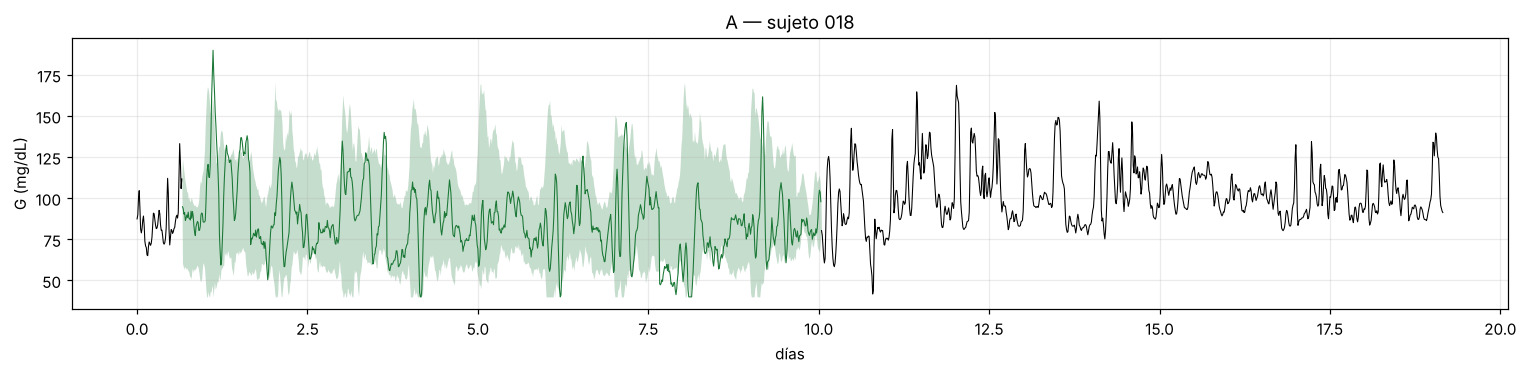

,Cohorte publicada,Plano H×C,Validación de eventos
Sano,15,15,14
Prediabético,16,15,15
Diabetes tipo 2,14,14,14
Total,45,44,43


In [2]:
qc = pd.DataFrame([dict(sujeto=i, grupo=r.grupo, dias=len(r.glucosa) / 96, dias_utilizables=r.dias_utilizables,
                        huecos_largos=len(r.huecos_largos), horas_reconstruir=sum(n for _, n in r.huecos_largos) / 4,
                        comidas=len(r.comidas)) for i, r in REG.items()])
display(qc[(qc.huecos_largos > 0) | (qc.dias_utilizables < cm.DIAS_MINIMOS)].round(2))

base = cm.BaseDCTPCA(cm.perfiles_diarios_sanos(list(REG.values())))
print(f"Base DCT-PCA: {base.n_perfiles} perfiles diarios sanos, {base.n_dct} coeficientes DCT, {base.n_pca} componentes "
      f"({100 * base.var_explicada:.1f} % de la variabilidad)")

SERIE, EXCLUIDOS_HC, EXCLUIDOS_EV = {}, [], []
for i, r in REG.items():
    if r.dias_utilizables < cm.DIAS_MINIMOS:
        EXCLUIDOS_HC.append(i); EXCLUIDOS_EV.append(i)
        print(f"Sujeto {i:03d}: {r.dias_utilizables:.1f} días utilizables (sin tramos fijados en el piso del sensor) "
              f"< {cm.DIAS_MINIMOS:.0f} → excluido")
    elif r.completo:
        SERIE[i] = r.glucosa
    else:
        reales, k, hc = cm.reconstruir(r, base, 100, semilla=42)
        SERIE[i] = reales[k]
        INFO_REC = dict(sujeto=i, huecos=len(r.huecos_largos), mayor_h=max(n for _, n in r.huecos_largos) / 4,
                        total_h=sum(n for _, n in r.huecos_largos) / 4, hc=hc,
                        dias_completos=int(sum(not np.isnan(r.glucosa[d * 96:(d + 1) * 96]).any() for d in range(len(r.glucosa) // 96))))
        if sum(n for _, n in r.huecos_largos) / 4 > 24:      # huecos > 1 día impiden comparar con las comidas
            EXCLUIDOS_EV.append(i)
        print(f"Sujeto {i:03d}: {len(r.huecos_largos)} huecos internos, {qc.loc[qc.sujeto == i, 'horas_reconstruir'].item():.1f} h "
              f"reconstruidas; 100 realizaciones con H ∈ [{hc[:, 0].min():.3f}, {hc[:, 0].max():.3f}], "
              f"C ∈ [{hc[:, 1].min():.3f}, {hc[:, 1].max():.3f}]")
        if i == 18:
            p5, p95 = np.percentile(reales, [5, 95], axis=0)
            fig, ax = plt.subplots(figsize=(14, 3.5)); t = np.arange(len(r.glucosa)) / 96
            ax.fill_between(t, p5, p95, color="#1b7837", alpha=.25, lw=0); ax.plot(t, r.glucosa, "k", lw=.7)
            ax.plot(t, np.where(np.isnan(r.glucosa), SERIE[i], np.nan), color="#1b7837", lw=.7)
            ax.set(xlabel="días", ylabel="G (mg/dL)", title="A — sujeto 018"); fig.tight_layout()
            fig.savefig(OUT / "figura_7_1A_reconstruccion_018.png", dpi=200); plt.show()
tabla_71 = pd.DataFrame({g: [sum(r.grupo == g for r in REG.values()),
                             sum(r.grupo == g for i, r in REG.items() if i not in EXCLUIDOS_HC),
                             sum(r.grupo == g for i, r in REG.items() if i not in EXCLUIDOS_EV)] for g in GRUPOS},
                        index=["Cohorte publicada", "Plano H×C", "Validación de eventos"]).T
tabla_71.loc["Total"] = tabla_71.sum(); tabla_71.to_csv(OUT / "tabla_7_1_cohorte.csv"); tabla_71

## 2. Plano entropía–complejidad (Sec. 7.4, Tabla 7.3, Fig. 7.1B)

,n,H,H_de,C,C_de
grupo,,,,,
Sano,15,0.841,0.044,0.128,0.025
Prediabético,15,0.810,0.033,0.150,0.021
Diabetes tipo 2,14,0.772,0.032,0.173,0.018


Kruskal–Wallis: H p = 1.47e-04, C p = 1.14e-04;  Mann–Whitney sano vs DT2: H p = 2.68e-04, C p = 2.26e-04


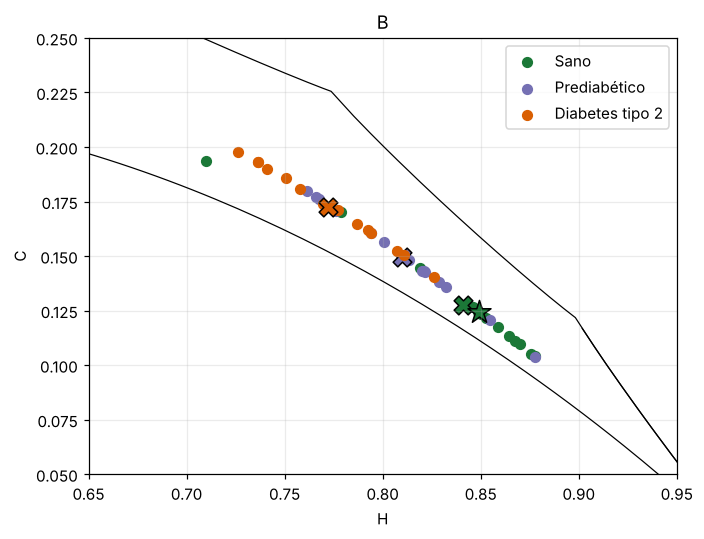

In [3]:
hc = pd.DataFrame([dict(sujeto=i, grupo=REG[i].grupo, H=ordinal.hxc(g)[0], C=ordinal.hxc(g)[1]) for i, g in SERIE.items()])
t73 = hc.groupby("grupo").agg(n=("H", "size"), H=("H", "mean"), H_de=("H", "std"), C=("C", "mean"), C_de=("C", "std")).loc[GRUPOS]
t73.round(3).to_csv(OUT / "tabla_7_3_hxc.csv"); display(t73.round(3))
kw_h = stats.kruskal(*[hc[hc.grupo == g].H for g in GRUPOS]).pvalue; kw_c = stats.kruskal(*[hc[hc.grupo == g].C for g in GRUPOS]).pvalue
mw_h = stats.mannwhitneyu(hc[hc.grupo == "Sano"].H, hc[hc.grupo == "Diabetes tipo 2"].H).pvalue
mw_c = stats.mannwhitneyu(hc[hc.grupo == "Sano"].C, hc[hc.grupo == "Diabetes tipo 2"].C).pvalue
print(f"Kruskal–Wallis: H p = {kw_h:.2e}, C p = {kw_c:.2e};  Mann–Whitney sano vs DT2: H p = {mw_h:.2e}, C p = {mw_c:.2e}")
hmin, cmin, hmax, cmax = ordinal.curvas_limite(3)
fig, ax = plt.subplots(figsize=(6.5, 5)); ax.plot(hmax, cmax, "k-", lw=.8); ax.plot(hmin, cmin, "k-", lw=.8)
for g in GRUPOS:
    d = hc[hc.grupo == g]; ax.scatter(d.H, d.C, color=COL[g], s=40, label=g); ax.scatter(d.H.mean(), d.C.mean(), color=COL[g], marker="X", s=150, ec="k")
if 18 in SERIE: ax.scatter(*hc[hc.sujeto == 18][["H", "C"]].to_numpy()[0], marker="*", s=250, color=COL["Sano"], ec="k")
ax.set(xlim=(.65, .95), ylim=(.05, .25), xlabel="H", ylabel="C", title="B"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "figura_7_1B_hxc.png", dpi=200); plt.show()

# Figura 7.1 — paneles A (reconstrucción del 018) y B (plano H × C) en una sola imagen
from PIL import Image
_a, _b = Image.open(OUT / "figura_7_1A_reconstruccion_018.png"), Image.open(OUT / "figura_7_1B_hxc.png")
_b = _b.resize((round(_b.width * _a.height / _b.height), _a.height))
_f = Image.new("RGB", (_a.width + _b.width, _a.height), "white"); _f.paste(_a, (0, 0)); _f.paste(_b, (_a.width, 0))
_f.save(OUT / "figura_7_1_reconstruccion_y_hxc.png")

## 3. Detector de ingestas frente a las comidas anotadas (Sec. 7.5, Tablas 7.4–7.5)

### 3.1 Código original del capítulo
Los scripts de `originales/cap7_cgmacros` se ejecutan sin cambios (sólo se hicieron
portables las rutas). `extract_St.py` calcula S(t) con la variante de la Sec. 3.3.5 (ventana
de 10 muestras, corte DCT del 10 %, sin raíz) sobre la serie Libre remuestreada a 15 min, y
`consolidar_3grupos.py` corre el detector: ventanas de 2,5 h, ΔG ≥ 20 mg/dL, Morlet
`cmor1.5-1.0` en la banda 0,5–2 h, puntaje Q ≥ 0,2, niveles fuerte/moderada/leve; una comida
cuenta como detectada si cae en [inicio − 45 min, fin] de alguna ventana. El alba usa la
ventana 03:00–08:00 con ΔG > 30 mg/dL. Luego se agrupa por HbA1c y se excluyen 007 y 018,
como en la versión final del capítulo. Si no están los CSV originales de CGMacros, se
reconstruyen a partir de la versión compacta del repositorio.

In [4]:
sys.path.insert(0, str(RAIZ / "originales" / "cap7_cgmacros"))
import reproducir as orig7
SAL7 = orig7.ejecutar(OUT / "original")
T7 = orig7.tablas(SAL7)
t74o, t75o, t76o = T7["t74"], T7["t75"], T7["t76"]
t74o.round(1).to_csv(OUT / "tabla_7_4_detector_original.csv"); t75o.to_csv(OUT / "tabla_7_5_intensidad_original.csv")
t76o.round(3).to_csv(OUT / "tabla_7_6_alba_original.csv")
display(t74o.round(1)); display(t75o); display(t76o.round(3))

$ python extract_St.py
CGMacros-047 1047 10.90   0.6227 -0.0053 0.1771 -0.614  0.622
CGMacros-048 1158 12.05   0.4031 -0.0026 0.1041 -0.383  0.403
CGMacros-049 1022 10.64   0.7601 -0.0199 0.2211 -0.758  0.721

45 sujetos procesados.


$ python consolidar_3grupos.py
grupo  n     H  H_sd     C  C_sd  recall  precision  alba_dia
        Sano 10 0.842 0.049 0.126 0.026   0.505      0.822     0.085
Prediabético 17 0.804 0.068 0.150 0.034   0.603      0.749     0.219
   Diabético 18 0.774 0.030 0.172 0.017   0.651      0.683     0.355


$ python detect_diabeticos.py
  fuerte   : 44/50 = 88.0%
  moderada : 127/162 = 78.4%
  leve     : 195/324 = 60.2%

Fenómeno del alba: 76 eventos en 17 sujetos


$ python plot_diab_burgers.py
ok 11 reales, 9 detectadas, 1 alba


,comidas,comidas_detectadas,detecciones,detecciones_correctas,sensibilidad_%,precision_%
grupo_tesis,,,,,,
Sano,595,297,307,238,49.9,77.5
Prediabético,600,401,459,351,66.8,76.5
Diabetes tipo 2,455,285,401,265,62.6,66.1


,fuerte,moderada,leve
grupo_tesis,,,
Sano,4,31,272
Prediabético,12,91,356
Diabetes tipo 2,43,122,236


,alba,dias,eventos_por_dia
grupo_tesis,,,
Sano,21,163,0.129
Prediabético,44,176,0.250
Diabetes tipo 2,61,166,0.367


### 3.2 Figura 7.2 — sujeto 029
`plot_diab_burgers.py` (script original) marca las comidas anotadas y las ventanas detectadas.

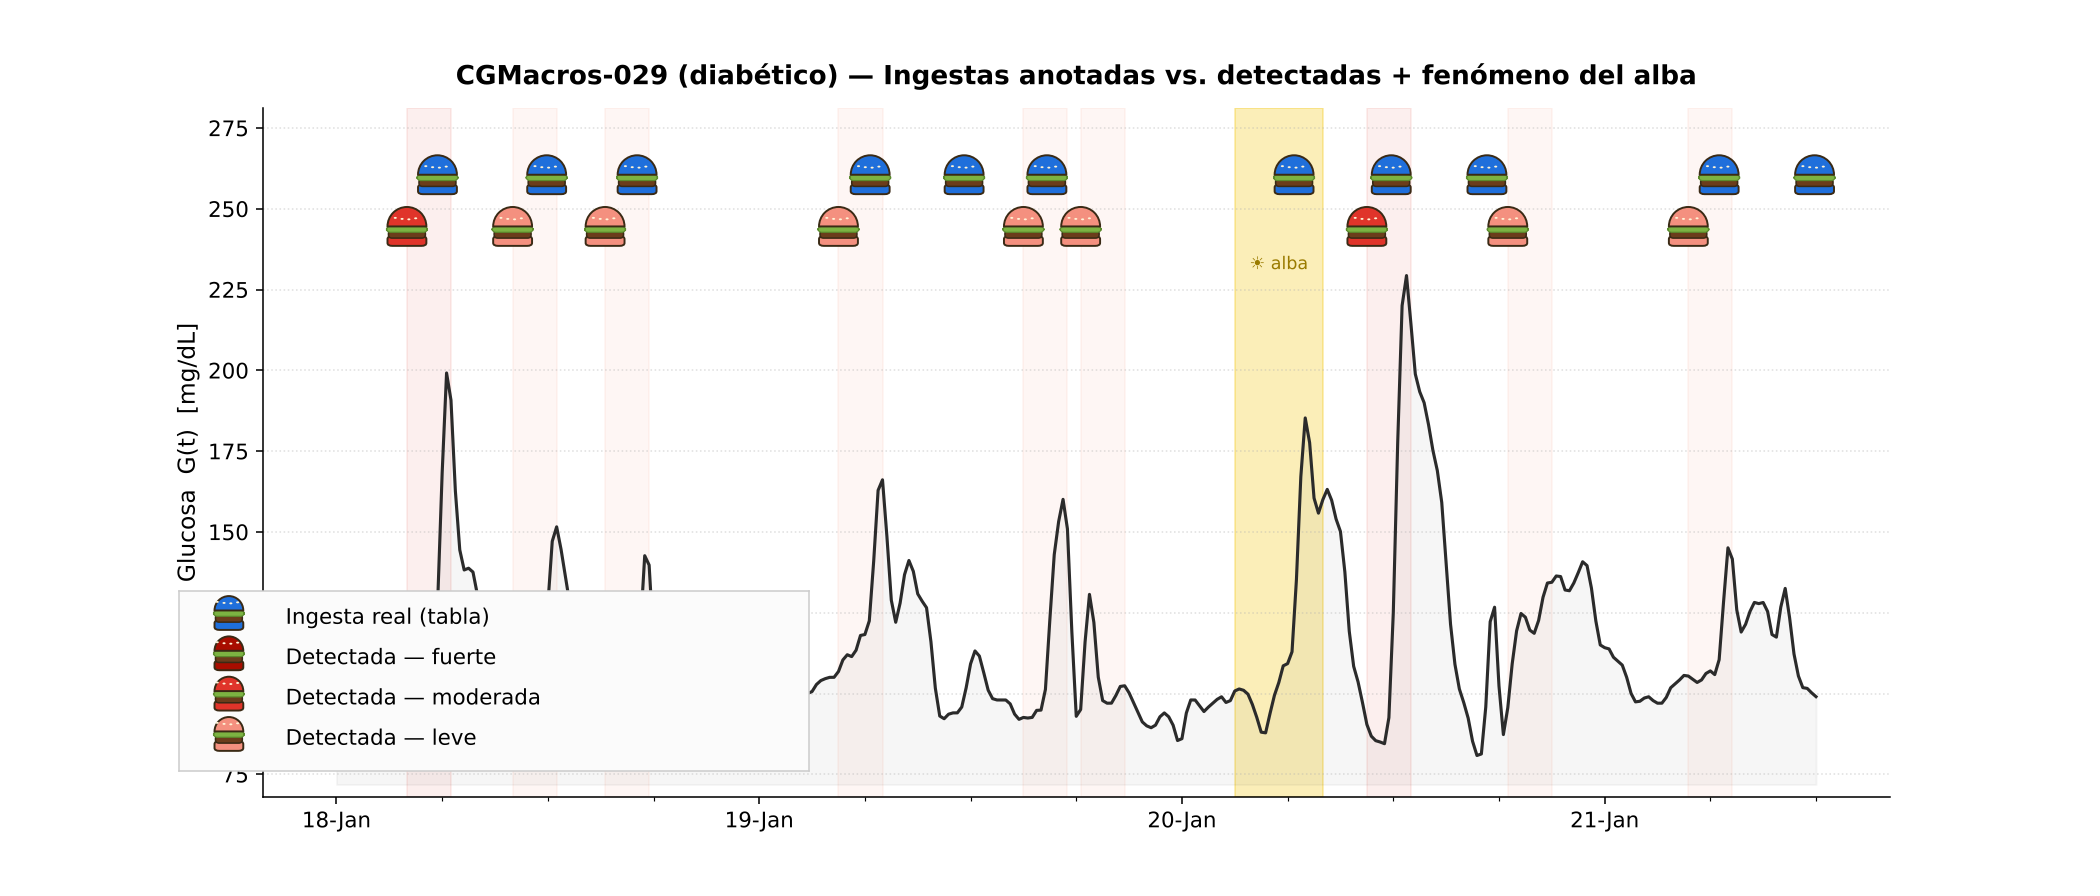

In [5]:
import shutil
from IPython.display import Image as _Img
shutil.copy(SAL7 / "diab_hamburguesas_029.png", OUT / "figura_7_2_sujeto_029.png")
_Img(filename=str(OUT / "figura_7_2_sujeto_029.png"))

## 4. Fenómeno del alba (Sec. 7.6, Tabla 7.6) y comparación entre grupos (Fig. 7.3)
La Tabla 7.6 proviene del código original (§3.1): ventana 03:00–08:00 con ΔG > 30 mg/dL.

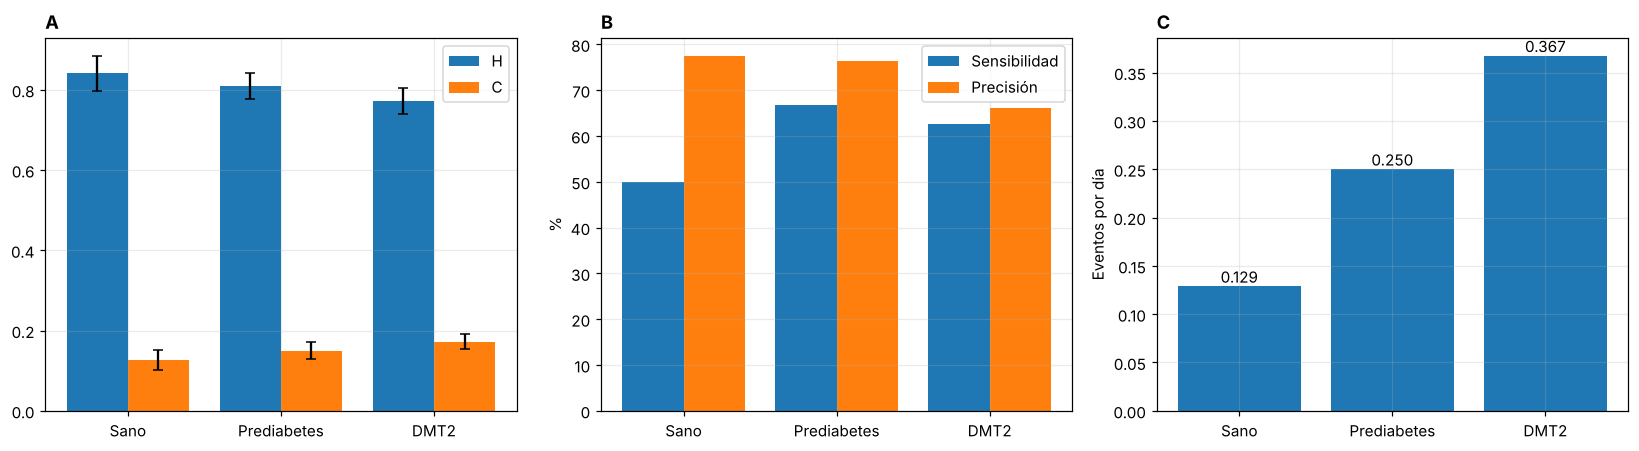

In [6]:
# Figura 7.3 — comparación entre las tres condiciones glucémicas
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
xg = np.arange(3); et = ["Sano", "Prediabetes", "DMT2"]
ax[0].bar(xg - .2, t73.H, .4, yerr=t73.H_de, capsize=3, color="#1f77b4", label="H")
ax[0].bar(xg + .2, t73.C, .4, yerr=t73.C_de, capsize=3, color="#ff7f0e", label="C")
ax[0].set_xticks(xg, et); ax[0].legend(); ax[0].set_title("A", loc="left", fontweight="bold")
ax[1].bar(xg - .2, t74o["sensibilidad_%"], .4, color="#1f77b4", label="Sensibilidad")
ax[1].bar(xg + .2, t74o["precision_%"], .4, color="#ff7f0e", label="Precisión")
ax[1].set_xticks(xg, et); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].set_title("B", loc="left", fontweight="bold")
bb = ax[2].bar(xg, t76o.eventos_por_dia, color="#1f77b4"); ax[2].bar_label(bb, fmt="%.3f")
ax[2].set_xticks(xg, et); ax[2].set_ylabel("Eventos por día"); ax[2].set_title("C", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "figura_7_3_comparacion_grupos.png", dpi=200); plt.show()

## 5. Ajuste del modelo en los 14 sujetos con diabetes tipo 2 (Sec. 7.7, Tabla 7.7)
El capítulo usó `sim_langevin.py` (extraído de `Simulador_DBT2.ipynb`) con 120 ensayos TPE
por sujeto, ejecutado con `run_sim_cgm.py` sobre `originales/cap7_cgmacros/cgm_diab_in`. El
ruido se sembró con `hash(sujeto)`, que Python aleatoriza en cada sesión, por lo que la
corrida no es repetible bit a bit; por eso se usan las trayectorias archivadas
(`archivado/series_simulacion_diabeticos.csv`). Los promedios de la Sec. 7.7 corresponden a
los 14 sujetos con HbA1c ≥ 6,5 %.

In [7]:
DT2 = [i for i in ids if REG[i].grupo == "Diabetes tipo 2"]
ser = pd.read_csv(RAIZ / "originales" / "cap7_cgmacros" / "archivado" / "series_simulacion_diabeticos.csv")
ser["sujeto"] = ser.subject.str[-3:].astype(int)
m7o = pd.DataFrame([dict(sujeto=i, **sdde.metricas_ajuste(x.G_real.to_numpy(), x.G_simulada.to_numpy()))
                    for i, x in ser[ser.sujeto.isin(DT2)].groupby("sujeto")])
print(f"{len(m7o)} sujetos — ρ medio {m7o.rho.mean():.3f}, RMSE medio {m7o.rmse.mean():.1f} mg/dL, "
      f"TIR real {m7o.TIR_real.mean():.1f} %, TIR simulado {m7o.TIR_sim.mean():.1f} %")
from decimal import Decimal, ROUND_HALF_UP
def red(x, d):   # redondeo «mitad hacia arriba», como en el resumen archivado
    return float(Decimal(repr(round(float(x), 9))).quantize(Decimal(1).scaleb(-d), rounding=ROUND_HALF_UP))
m7a = orig7.modelo_archivado()                       # resumen por sujeto de la corrida original
t77 = pd.DataFrame({"Real": [np.nan, np.nan, red(m7a.H_real.mean(), 3), red(m7a.C_real.mean(), 3), red(100 * m7a.TIR_real.mean(), 1), red(m7a.beta_real.mean(), 2)],
                    "Simulado": [red(m7a["corr"].mean(), 3), red(m7a.rmse.mean(), 1), red(m7a.H_sim.mean(), 3), red(m7a.C_sim.mean(), 3),
                                 red(100 * m7a.TIR_sim.mean(), 1), red(m7a.beta_sim.mean(), 2)],
                    "DE": [red(m7a["corr"].std(), 3), red(m7a.rmse.std(), 1), np.nan, np.nan, np.nan, np.nan]},
                   index=["Correlación temporal", "RMSE (mg/dL)", "Entropía H", "Complejidad C", "Tiempo en rango (%)", "Exponente espectral β"])
t77.to_csv(OUT / "tabla_7_7_modelo.csv")
r_tir = np.corrcoef(m7a.TIR_real, m7a.TIR_sim)[0, 1]
print(f"r(TIR real, TIR simulado) entre sujetos = {red(r_tir, 3):.3f}")
t77

14 sujetos — ρ medio 0.739, RMSE medio 24.7 mg/dL, TIR real 81.9 %, TIR simulado 81.0 %
r(TIR real, TIR simulado) entre sujetos = 0.947


,Real,Simulado,DE
Correlación temporal,NaN,0.739,0.148
RMSE (mg/dL),NaN,24.800,9.000
Entropía H,0.775,0.792,NaN
Complejidad C,0.171,0.161,NaN
Tiempo en rango (%),82.000,81.000,NaN
Exponente espectral β,2.530,2.390,NaN


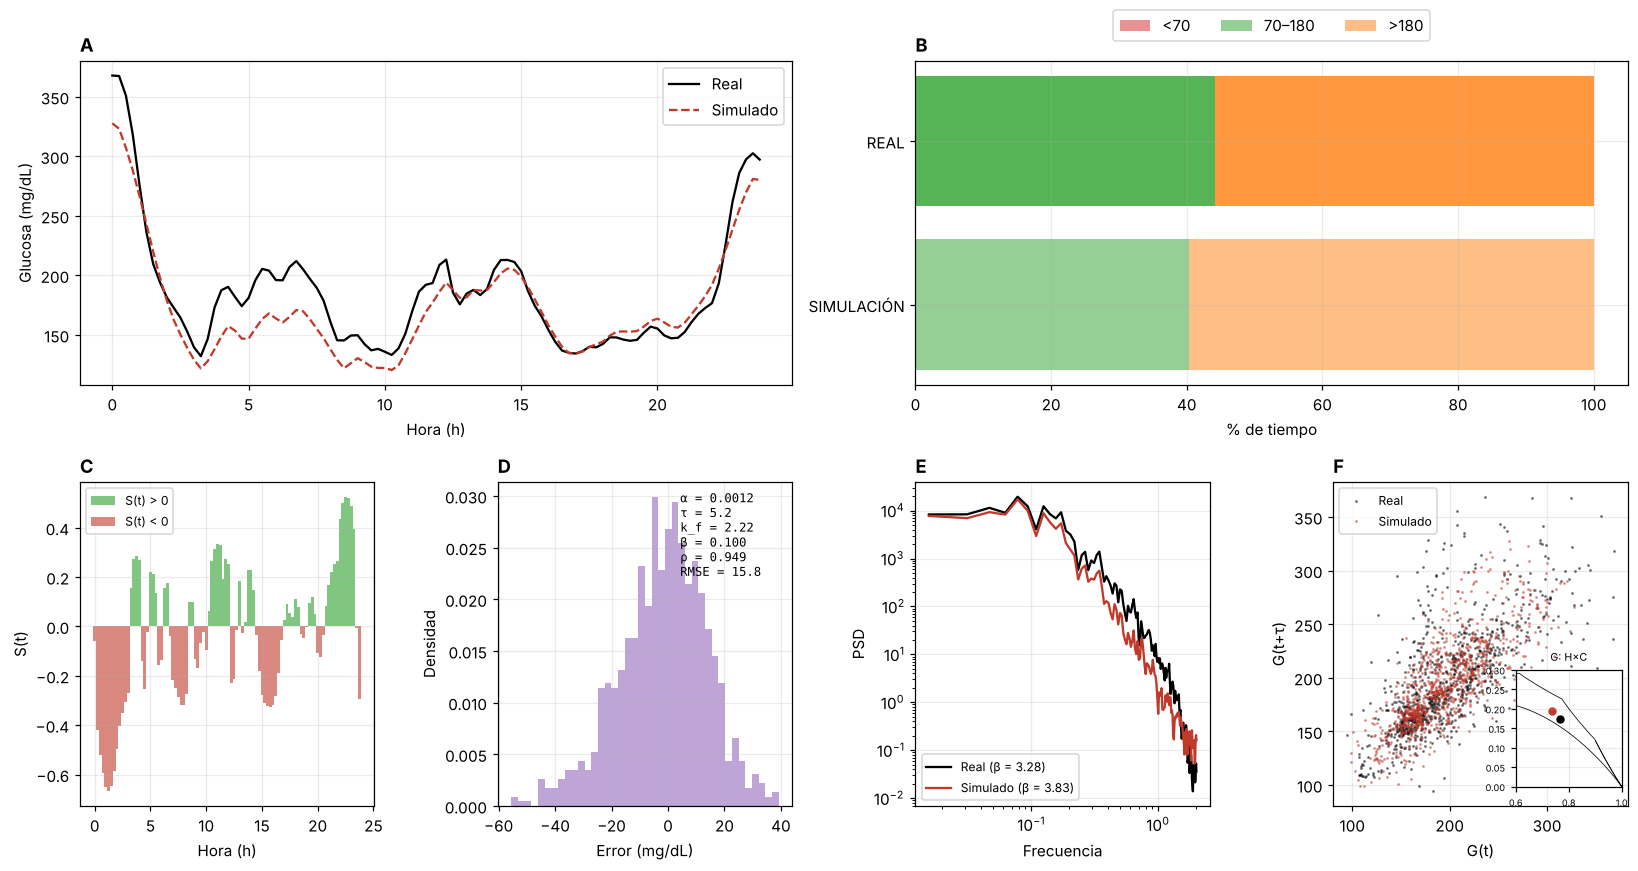

In [8]:
# Figura 7.4 — panel de validación de CGMacros-035 con la simulación archivada
arch = pd.read_csv(RAIZ / "originales" / "cap7_cgmacros" / "archivado" / "sim_CGM_diab_resumen.csv").set_index("ID")
x35 = ser[ser.sujeto == 35]; gr, gsim = x35.G_real.to_numpy(), x35.G_simulada.to_numpy(); p35 = arch.loc[35]
s35 = forzamiento(gr); m35 = sdde.metricas_ajuste(gr, gsim)
fig = plt.figure(figsize=(15, 8)); gsp = fig.add_gridspec(2, 4)
t = np.arange(96) / 4; dsl = slice(96, 192)
a = fig.add_subplot(gsp[0, :2]); a.plot(t, gr[dsl], "k", label="Real"); a.plot(t, gsim[dsl], "--", color="#c0392b", label="Simulado")
a.set(xlabel="Hora (h)", ylabel="Glucosa (mg/dL)"); a.legend(); a.set_title("A", loc="left", fontweight="bold")
b = fig.add_subplot(gsp[0, 2:]); cr, cs = sdde.metricas_clinicas(gr), sdde.metricas_clinicas(gsim)
for y_, (nom, c_) in enumerate((("SIMULACIÓN", cs), ("REAL", cr))):
    izq = 0
    for k_, col_ in (("TBR", "#d62728"), ("TIR", "#2ca02c"), ("TAR", "#ff7f0e")):
        b.barh(y_, 100 * c_[k_], left=izq, color=col_, alpha=.8 if nom == "REAL" else .5, label=k_ if y_ == 0 else None); izq += 100 * c_[k_]
b.set_yticks([0, 1], ["SIMULACIÓN", "REAL"]); b.set_xlabel("% de tiempo"); b.legend(["<70", "70–180", ">180"], ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.18))
b.set_title("B", loc="left", fontweight="bold")
c = fig.add_subplot(gsp[1, 0]); tt = np.arange(96) / 4; sc = s35[dsl]
c.bar(tt, np.where(sc > 0, sc, 0), width=.25, color="#2ca02c", alpha=.6, label="S(t) > 0"); c.bar(tt, np.where(sc < 0, sc, 0), width=.25, color="#c0392b", alpha=.6, label="S(t) < 0")
c.set(xlabel="Hora (h)", ylabel="S(t)"); c.legend(fontsize=8); c.set_title("C", loc="left", fontweight="bold")
d = fig.add_subplot(gsp[1, 1]); d.hist(gsim - gr, bins=40, density=True, color="#9467bd", alpha=.6)
d.text(.62, .97, f"α = {p35.alpha:.4f}\nτ = {p35.tau:.1f}\nk_f = {p35.k_f:.2f}\nβ = {p35.beta:.3f}\nρ = {m35['rho']:.3f}\nRMSE = {m35['rmse']:.1f}",
       transform=d.transAxes, va="top", fontsize=8, family="monospace"); d.set(xlabel="Error (mg/dL)", ylabel="Densidad"); d.set_title("D", loc="left", fontweight="bold")
e = fig.add_subplot(gsp[1, 2])
for y_, col_, lab in ((gr, "k", "Real"), (gsim, "#c0392b", "Simulado")):
    fq, pw = espectral.psd(y_); k_ = fq > 0
    e.loglog(fq[k_], pw[k_], color=col_, label=f"{lab} (β = {espectral.beta_welch(y_):.2f})")
e.set(xlabel="Frecuencia", ylabel="PSD"); e.legend(fontsize=8); e.set_title("E", loc="left", fontweight="bold")
f_ = fig.add_subplot(gsp[1, 3]); te = 4
f_.plot(gr[:-te], gr[te:], ".", ms=2, color="k", alpha=.4, label="Real"); f_.plot(gsim[:-te], gsim[te:], ".", ms=2, color="#c0392b", alpha=.4, label="Simulado")
f_.set(xlabel="G(t)", ylabel="G(t+τ)"); f_.legend(fontsize=8); f_.set_title("F", loc="left", fontweight="bold")
ins = f_.inset_axes([.62, .06, .36, .36]); ins.plot(hmax, cmax, "k-", lw=.5); ins.plot(hmin, cmin, "k-", lw=.5)
ins.scatter(m35["H_real"], m35["C_real"], c="k", s=20); ins.scatter(m35["H_sim"], m35["C_sim"], c="#c0392b", s=20)
ins.set(xlim=(.6, 1), ylim=(0, .3)); ins.set_title("G: H×C", fontsize=7); ins.tick_params(labelsize=6)
fig.tight_layout(); fig.savefig(OUT / "figura_7_4_panel_035.png", dpi=200); plt.show()

## 6. Intervención in silico con seguridad ante hipoglucemia (Sec. 7.8)
Tres trayectorias por sujeto, con la misma realización de ruido:
1. referencia (S original);
2. atenuación posprandial (6.5) + actualización causal de B(t) (6.6b), sin respuesta rápida;
3. lo anterior + respuesta rápida de S(t) (6.7a–j) con los parámetros de la Tabla 7.8.

El vector ρ se optimiza como en la Sec. 6.12 (objetivo HbA1c eq. ≤ 5,5 %, 250 ensayos TPE)
y se reutiliza en el escenario 3; salvaguarda inferior del integrador 20 mg/dL.

### 6.1 Parámetros de la intervención
Para la intervención, cada sujeto se calibra con el paquete `glucosa`: misma ecuación, integrador y función objetivo del Capítulo 4 (300 ensayos TPE, filtro de
Savitzky–Golay), tres corridas con semillas 42, 1 y 2, y se conserva la de menor J(θ).
Los parámetros se guardan en `resultados/cap7/parametros_cgmacros_DT2.csv`.

In [9]:
ruta_p = OUT / "parametros_cgmacros_DT2.csv"
if ruta_p.exists():
    PAR = pd.read_csv(ruta_p, float_precision="round_trip").set_index("sujeto")
    PAR_J = PAR.pop("J") if "J" in PAR else None
else:
    filas = []
    for i in DT2:
        corridas = [sdde.ajustar(SERIE[i], n_ensayos=300, semilla_optuna=sd, filtro_sg=True) for sd in (42, 1, 2)]
        best, est = min(corridas, key=lambda c: c[1].best_value)
        filas.append(dict(sujeto=i, **best, J=est.best_value))
    PAR = pd.DataFrame(filas).set_index("sujeto"); PAR.to_csv(ruta_p, float_format="%.17g"); PAR_J = PAR.pop("J")

In [10]:
print("Tabla 7.8 — parámetros de la respuesta rápida:", iv.SEGURIDAD)
pd.Series(iv.SEGURIDAD, name="valor").to_csv(OUT / "tabla_7_8_parametros_respuesta_rapida.csv")
filas, curvas = [], {}
for i in DT2:
    g = SERIE[i]; p = {**PAR.loc[i].to_dict(), "filtro_sg": True}; s = forzamiento(g)
    ruido = sdde.ruido_blanco(len(g))
    g_ref = sdde.simular(g, ruido=ruido, g_min=20.0, **p)
    ev = [(e.inicio, e.fin) for e in detector.detectar_ingestas(g_ref, s, desfase=REG[i].desfase)]
    R = iv.optimizar(g, p, ev, a1c_obj=5.5, n_ensayos=250, semilla=42, g_referencia=g_ref, g_min=20.0)
    s_at = iv.atenuar(s, ev, R.rho)
    g_sin = iv.simular_intervencion(g, p, s_at, ruido=ruido, g_min=20.0)
    g_con = iv.simular_intervencion(g, p, s_at, seguridad=iv.SEGURIDAD, ruido=ruido, g_min=20.0)
    r0, r1, r2 = iv.resumen(g_ref), iv.resumen(g_sin), iv.resumen(g_con)
    curvas[i] = (g_ref, g_sin, g_con)
    filas.append(dict(sujeto=i, A1c_ref=r0["A1c"], A1c_sin=r1["A1c"], A1c_con=r2["A1c"], TIR_ref=r0["TIR"], TIR_sin=r1["TIR"], TIR_con=r2["TIR"],
                      TBR_sin=r1["TBR"], TBR_con=r2["TBR"], TBR54_sin=r1["TBR54"], TBR54_con=r2["TBR54"],
                      hipo_max_sin_h=r1["hipo_max_h"], hipo_max_con_h=r2["hipo_max_h"], minimo_con=g_con.min()))
t79 = pd.DataFrame(filas).sort_values("A1c_ref", ascending=False)
t79.round(2).to_csv(OUT / "tabla_7_9_intervencion.csv", index=False)
print(f"HbA1c eq. media: ref {t79.A1c_ref.mean():.2f} %, sin respuesta {t79.A1c_sin.mean():.2f} %, con respuesta {t79.A1c_con.mean():.2f} %")
print(f"TIR {t79.TIR_ref.mean():.1f} → {t79.TIR_con.mean():.1f} %;  TBR<70 {t79.TBR_sin.mean():.2f} → {t79.TBR_con.mean():.2f} %;  "
      f"TBR<54 {t79.TBR54_sin.mean():.2f} → {t79.TBR54_con.mean():.2f} %;  episodio máx. {t79.hipo_max_sin_h.max():.2f} → {t79.hipo_max_con_h.max():.2f} h;  "
      f"sujetos < 7 %: {np.sum(t79.A1c_con < 7)}/14;  mínimo simulado {t79.minimo_con.min():.1f} mg/dL")
t79.round(2)

Tabla 7.8 — parámetros de la respuesta rápida: {'k_d': 0.3, 'k_v': 0.02, 'gamma_n': 1.0, 'S_h_max': 0.75, 'tau_ataque': 10.0, 'tau_retorno': 60.0}


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HbA1c eq. media: ref 6.42 %, sin respuesta 5.79 %, con respuesta 6.10 %
TIR 81.0 → 89.1 %;  TBR<70 4.89 → 1.54 %;  TBR<54 1.88 → 0.04 %;  episodio máx. 13.00 → 1.75 h;  sujetos < 7 %: 14/14;  mínimo simulado 53.2 mg/dL


,sujeto,A1c_ref,A1c_sin,A1c_con,TIR_ref,TIR_sin,TIR_con,TBR_sin,TBR_con,TBR54_sin,TBR54_con,hipo_max_sin_h,hipo_max_con_h,minimo_con
6,35,8.45,6.40,6.56,43.18,84.39,84.18,2.19,0.94,0.00,0.00,2.50,1.00,66.18
11,46,7.64,6.32,6.62,58.78,78.67,77.86,3.88,1.12,2.24,0.10,2.50,1.00,53.70
2,12,7.37,5.84,6.53,64.96,82.64,81.92,8.89,3.06,6.03,0.41,4.50,1.75,53.18
12,47,7.07,5.62,5.70,79.47,93.79,94.84,2.20,0.76,0.29,0.00,2.50,1.00,62.08
5,30,7.03,6.43,6.94,70.16,73.45,72.67,6.59,1.45,2.81,0.00,4.75,1.00,63.06
13,49,6.47,5.89,6.49,80.92,84.74,84.05,7.34,2.15,3.82,0.00,3.25,1.50,55.80
9,39,6.45,6.16,6.49,84.15,85.10,85.28,4.01,1.57,1.39,0.00,2.75,1.50,59.06
10,42,6.27,5.58,5.64,98.35,97.21,98.45,2.58,1.24,0.62,0.00,2.75,1.75,64.27
8,38,5.70,5.50,5.75,95.35,94.94,95.35,1.86,0.72,0.31,0.00,1.75,1.00,62.97
4,28,5.61,5.50,5.62,98.64,98.80,99.28,1.20,0.64,0.16,0.00,1.75,1.00,61.22


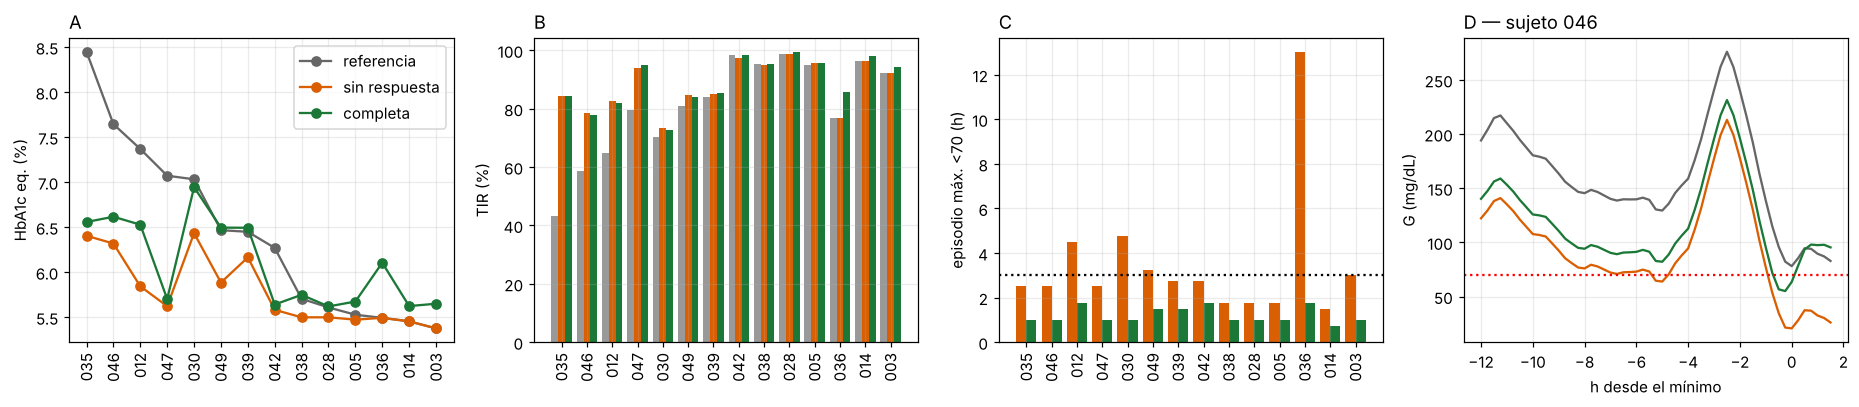

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
x = np.arange(len(t79))
ax[0].plot(x, t79.A1c_ref, "o-", color="0.4", label="referencia"); ax[0].plot(x, t79.A1c_sin, "o-", color="#d95f02", label="sin respuesta"); ax[0].plot(x, t79.A1c_con, "o-", color="#1b7837", label="completa")
ax[0].set_xticks(x, [f"{i:03d}" for i in t79.sujeto], rotation=90); ax[0].set_ylabel("HbA1c eq. (%)"); ax[0].legend(); ax[0].set_title("A", loc="left")
ax[1].bar(x - .27, t79.TIR_ref, .27, color="0.6"); ax[1].bar(x, t79.TIR_sin, .27, color="#d95f02"); ax[1].bar(x + .27, t79.TIR_con, .27, color="#1b7837")
ax[1].set_xticks(x, [f"{i:03d}" for i in t79.sujeto], rotation=90); ax[1].set_ylabel("TIR (%)"); ax[1].set_title("B", loc="left")
ax[2].bar(x - .2, t79.hipo_max_sin_h, .4, color="#d95f02"); ax[2].bar(x + .2, t79.hipo_max_con_h, .4, color="#1b7837"); ax[2].axhline(3, color="k", ls=":"); ax[2].set_xticks(x, [f"{i:03d}" for i in t79.sujeto], rotation=90)
ax[2].set_ylabel("episodio máx. <70 (h)"); ax[2].set_title("C", loc="left")
if 46 in curvas:
    g0, g1, g2 = curvas[46]; k = int(np.argmin(g1)); sl = slice(max(0, k - 48), k + 48); tt = (np.arange(len(g1))[sl] - k) / 4
    ax[3].plot(tt, g0[sl], color="0.4"); ax[3].plot(tt, g1[sl], color="#d95f02"); ax[3].plot(tt, g2[sl], color="#1b7837"); ax[3].axhline(70, color="r", ls=":")
    ax[3].set(xlabel="h desde el mínimo", ylabel="G (mg/dL)"); ax[3].set_title("D — sujeto 046", loc="left")
fig.tight_layout(); fig.savefig(OUT / "figura_7_5_intervencion.png", dpi=200); plt.show()

## Verificación de las cifras del capítulo
`✔` indica coincidencia con el valor del texto de la tesis al redondeo con que se informa.

In [12]:
def fila(dato, tesis, obtenido, dec):
    o = round(float(obtenido), dec)
    return dict(Dato=dato, Tesis=tesis, Reproducido=o, Coincide="✔" if abs(o - tesis) < 1e-9 else "✘")

CIFRAS_7 = [
    *[(f"Comidas anotadas — {g}", t74o.loc[g, "comidas"], 0) for g in GRUPOS],
    ("Sujeto 007: días utilizables", REG[7].dias_utilizables, 1),
    ("Sujeto 018: huecos internos", INFO_REC["huecos"], 0), ("Sujeto 018: hueco mayor (h)", INFO_REC["mayor_h"], 0),
    ("Sujeto 018: horas reconstruidas", INFO_REC["total_h"], 0), ("Sujeto 018: días completos", INFO_REC["dias_completos"], 0),
    ("Sujeto 018: H mínima", INFO_REC["hc"][:, 0].min(), 3), ("Sujeto 018: H máxima", INFO_REC["hc"][:, 0].max(), 3),
    ("Sujeto 018: C mínima", INFO_REC["hc"][:, 1].min(), 3), ("Sujeto 018: C máxima", INFO_REC["hc"][:, 1].max(), 3),
    ("Perfiles diarios de la base DCT-PCA", base.n_perfiles, 0), ("Varianza explicada por la base (%)", 100 * base.var_explicada, 1),
    ("Tabla 7.1: cohorte publicada", tabla_71.loc["Total", "Cohorte publicada"], 0),
    ("Tabla 7.1: plano H×C", tabla_71.loc["Total", "Plano H×C"], 0),
    ("Tabla 7.1: validación de eventos", tabla_71.loc["Total", "Validación de eventos"], 0),
    *[(f"Tabla 7.3 {g}: {c}", t73.loc[g, c], 0 if c == "n" else 3) for g in GRUPOS for c in ("n", "H", "H_de", "C", "C_de")],
    ("Kruskal–Wallis H: p (×10⁻⁴)", 1e4 * kw_h, 2), ("Kruskal–Wallis C: p (×10⁻⁴)", 1e4 * kw_c, 2),
    ("Mann–Whitney H sano vs DT2: p (×10⁻⁴)", 1e4 * mw_h, 2), ("Mann–Whitney C sano vs DT2: p (×10⁻⁴)", 1e4 * mw_c, 2),
    *[(f"Tabla 7.4 {g}: {c}", t74o.loc[g, c], 1 if c.endswith("%") else 0) for g in GRUPOS
      for c in ("detecciones", "sensibilidad_%", "precision_%")],
    *[(f"Tabla 7.5 {g}: {c}", t75o.loc[g, c], 0) for g in GRUPOS for c in ("fuerte", "moderada", "leve")],
    *[(f"Tabla 7.6 {g}: {c}", t76o.loc[g, c], 3 if c == "eventos_por_dia" else 0) for g in GRUPOS for c in ("alba", "dias", "eventos_por_dia")],
    ("Tabla 7.7: ρ medio", t77.loc["Correlación temporal", "Simulado"], 3), ("Tabla 7.7: ρ DE", t77.loc["Correlación temporal", "DE"], 3),
    ("Tabla 7.7: RMSE medio", t77.loc["RMSE (mg/dL)", "Simulado"], 1), ("Tabla 7.7: RMSE DE", t77.loc["RMSE (mg/dL)", "DE"], 1),
    *[(f"Tabla 7.7 {d}: {c}", t77.loc[d, c], 1 if "rango" in d else 2 if "β" in d else 3)
      for d in ("Entropía H", "Complejidad C", "Tiempo en rango (%)", "Exponente espectral β") for c in ("Real", "Simulado")],
    ("r(TIR real, TIR simulado)", red(r_tir, 3), 3),
    ("Intervención: HbA1c ref (%)", t79.A1c_ref.mean(), 2), ("Intervención: HbA1c sin respuesta (%)", t79.A1c_sin.mean(), 2),
    ("Intervención: HbA1c completa (%)", t79.A1c_con.mean(), 2),
    ("Intervención: TIR referencia (%)", t79.TIR_ref.mean(), 1), ("Intervención: TIR sin respuesta (%)", t79.TIR_sin.mean(), 1), ("Intervención: TIR completa (%)", t79.TIR_con.mean(), 1),
    ("Intervención: TBR<70 sin respuesta (%)", t79.TBR_sin.mean(), 2), ("Intervención: TBR<70 completa (%)", t79.TBR_con.mean(), 2),
    ("Intervención: TBR<54 sin respuesta (%)", t79.TBR54_sin.mean(), 2), ("Intervención: TBR<54 completa (%)", t79.TBR54_con.mean(), 2),
    ("Intervención: episodio máx. sin respuesta (h)", t79.hipo_max_sin_h.max(), 2),
    ("Intervención: episodio máx. completa (h)", t79.hipo_max_con_h.max(), 2),
    ("Intervención: sujetos > 7 % (completa)", np.sum(t79.A1c_con > 7), 0),
]
TESIS_7 = {  # cifras del texto del capítulo
    'Comidas anotadas — Sano': 595.0,
    'Comidas anotadas — Prediabético': 600.0,
    'Comidas anotadas — Diabetes tipo 2': 455.0,
    'Sujeto 007: días utilizables': 5.3,
    'Sujeto 018: huecos internos': 1.0,
    'Sujeto 018: hueco mayor (h)': 225.0,
    'Sujeto 018: horas reconstruidas': 225.0,
    'Sujeto 018: días completos': 8.0,
    'Sujeto 018: H mínima': 0.83,
    'Sujeto 018: H máxima': 0.865,
    'Sujeto 018: C mínima': 0.113,
    'Sujeto 018: C máxima': 0.137,
    'Perfiles diarios de la base DCT-PCA': 118.0,
    'Varianza explicada por la base (%)': 98.4,
    'Tabla 7.1: cohorte publicada': 45.0,
    'Tabla 7.1: plano H×C': 44.0,
    'Tabla 7.1: validación de eventos': 43.0,
    'Tabla 7.3 Sano: n': 15.0,
    'Tabla 7.3 Sano: H': 0.841,
    'Tabla 7.3 Sano: H_de': 0.044,
    'Tabla 7.3 Sano: C': 0.128,
    'Tabla 7.3 Sano: C_de': 0.025,
    'Tabla 7.3 Prediabético: n': 15.0,
    'Tabla 7.3 Prediabético: H': 0.81,
    'Tabla 7.3 Prediabético: H_de': 0.033,
    'Tabla 7.3 Prediabético: C': 0.15,
    'Tabla 7.3 Prediabético: C_de': 0.021,
    'Tabla 7.3 Diabetes tipo 2: n': 14.0,
    'Tabla 7.3 Diabetes tipo 2: H': 0.772,
    'Tabla 7.3 Diabetes tipo 2: H_de': 0.032,
    'Tabla 7.3 Diabetes tipo 2: C': 0.173,
    'Tabla 7.3 Diabetes tipo 2: C_de': 0.018,
    'Kruskal–Wallis H: p (×10⁻⁴)': 1.47,
    'Kruskal–Wallis C: p (×10⁻⁴)': 1.14,
    'Mann–Whitney H sano vs DT2: p (×10⁻⁴)': 2.68,
    'Mann–Whitney C sano vs DT2: p (×10⁻⁴)': 2.26,
    'Tabla 7.4 Sano: detecciones': 307.0,
    'Tabla 7.4 Sano: sensibilidad_%': 49.9,
    'Tabla 7.4 Sano: precision_%': 77.5,
    'Tabla 7.4 Prediabético: detecciones': 459.0,
    'Tabla 7.4 Prediabético: sensibilidad_%': 66.8,
    'Tabla 7.4 Prediabético: precision_%': 76.5,
    'Tabla 7.4 Diabetes tipo 2: detecciones': 401.0,
    'Tabla 7.4 Diabetes tipo 2: sensibilidad_%': 62.6,
    'Tabla 7.4 Diabetes tipo 2: precision_%': 66.1,
    'Tabla 7.5 Sano: fuerte': 4.0,
    'Tabla 7.5 Sano: moderada': 31.0,
    'Tabla 7.5 Sano: leve': 272.0,
    'Tabla 7.5 Prediabético: fuerte': 12.0,
    'Tabla 7.5 Prediabético: moderada': 91.0,
    'Tabla 7.5 Prediabético: leve': 356.0,
    'Tabla 7.5 Diabetes tipo 2: fuerte': 43.0,
    'Tabla 7.5 Diabetes tipo 2: moderada': 122.0,
    'Tabla 7.5 Diabetes tipo 2: leve': 236.0,
    'Tabla 7.6 Sano: alba': 21.0,
    'Tabla 7.6 Sano: dias': 163.0,
    'Tabla 7.6 Sano: eventos_por_dia': 0.129,
    'Tabla 7.6 Prediabético: alba': 44.0,
    'Tabla 7.6 Prediabético: dias': 176.0,
    'Tabla 7.6 Prediabético: eventos_por_dia': 0.25,
    'Tabla 7.6 Diabetes tipo 2: alba': 61.0,
    'Tabla 7.6 Diabetes tipo 2: dias': 166.0,
    'Tabla 7.6 Diabetes tipo 2: eventos_por_dia': 0.367,
    'Tabla 7.7: ρ medio': 0.739,
    'Tabla 7.7: ρ DE': 0.148,
    'Tabla 7.7: RMSE medio': 24.8,
    'Tabla 7.7: RMSE DE': 9.0,
    'Tabla 7.7 Entropía H: Real': 0.775,
    'Tabla 7.7 Entropía H: Simulado': 0.792,
    'Tabla 7.7 Complejidad C: Real': 0.171,
    'Tabla 7.7 Complejidad C: Simulado': 0.161,
    'Tabla 7.7 Tiempo en rango (%): Real': 82.0,
    'Tabla 7.7 Tiempo en rango (%): Simulado': 81.0,
    'Tabla 7.7 Exponente espectral β: Real': 2.53,
    'Tabla 7.7 Exponente espectral β: Simulado': 2.39,
    'r(TIR real, TIR simulado)': 0.947,
    'Intervención: HbA1c ref (%)': 6.42,
    'Intervención: HbA1c sin respuesta (%)': 5.79,
    'Intervención: HbA1c completa (%)': 6.1,
    'Intervención: TIR referencia (%)': 81.0,
    'Intervención: TIR sin respuesta (%)': 88.2,
    'Intervención: TIR completa (%)': 89.1,
    'Intervención: TBR<70 sin respuesta (%)': 4.89,
    'Intervención: TBR<70 completa (%)': 1.54,
    'Intervención: TBR<54 sin respuesta (%)': 1.88,
    'Intervención: TBR<54 completa (%)': 0.04,
    'Intervención: episodio máx. sin respuesta (h)': 13.0,
    'Intervención: episodio máx. completa (h)': 1.75,
    'Intervención: sujetos > 7 % (completa)': 0.0,
}
ver = pd.DataFrame([fila(d, TESIS_7[d], o, k) for d, o, k in CIFRAS_7])
ver.to_csv(OUT / "verificacion_cap7.csv", index=False); ver

,Dato,Tesis,Reproducido,Coincide
0,Comidas anotadas — Sano,595.00,595.00,✔
1,Comidas anotadas — Prediabético,600.00,600.00,✔
2,Comidas anotadas — Diabetes tipo 2,455.00,455.00,✔
3,Sujeto 007: días utilizables,5.30,5.30,✔
4,Sujeto 018: huecos internos,1.00,1.00,✔
...,...,...,...,...
84,Intervención: TBR<54 sin respuesta (%),1.88,1.88,✔
85,Intervención: TBR<54 completa (%),0.04,0.04,✔
86,Intervención: episodio máx. sin respuesta (h),13.00,13.00,✔
87,Intervención: episodio máx. completa (h),1.75,1.75,✔
